### Specifications:

    sampling frequency = 200 Hz
    passband = 40-60 Hz
    lower stopband = 0-10 Hz
    upper stopband = 90-100 Hz
    maximum passband error = 10%
    minimum attenuation in both stopbands = 20 dB

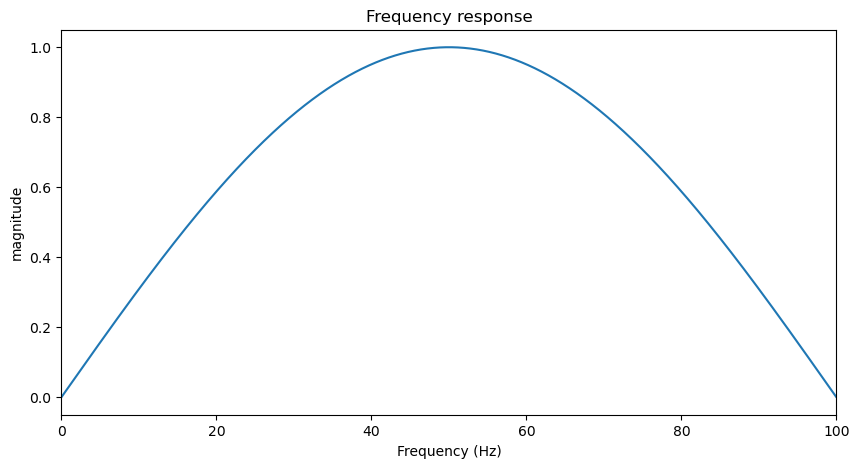

passband error = %4.856
stopband left (dB) = 10.233
stopband right (dB) = 10.233


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, freqz

fs = 200
#Adding zero at 0 Hz
b1 = np.array([1, -1])
#Adding zero at 100 Hz
b2 = np.array([1, 1])
b = np.convolve(b1, b2)

#Normalizing coefficients at 50 Hz       ### for a band-pass filter we can normalize at the center of its passband ###
f50, H50 = freqz(b, [1], worN = [50], fs=fs)
gain50 = np.abs(H50)
b = b / gain50

#frequency response
f, H = freqz(b, [1], worN=2048, fs=fs)
magnitude = np.abs(H)

#passband error
passband = (f >= 40) & (f <= 60)
passband_error = np.max(np.abs(magnitude[passband] - 1)) * 100
#stopbandleft
stopbandleft = (f <= 10)
stopband_att_dB_left = -20 * np.log10(np.max(magnitude[stopbandleft]))
#stopbandright
stopbandright = (f >= 90)
stopband_att_dB_right = -20 * np.log10(np.max(magnitude[stopbandright]))
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude)
plt.xlabel("Frequency (Hz)")
plt.ylabel("magnitude")
plt.title("Frequency response")
plt.xlim(0, 100)
plt.show()
print(f"passband error = %{passband_error:.3f}\nstopband left (dB) = {stopband_att_dB_left:.3f}\nstopband right (dB) = {stopband_att_dB_right:.3f}")


The designed FIR filter preserves the desired frequencies sufficiently well, but it does not suppress the stopbands strongly enough.

I try to improve the filter by repeating zeros:

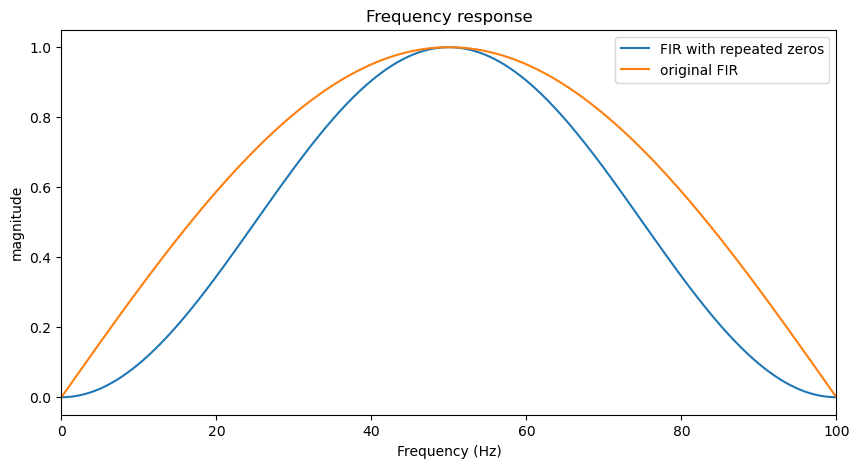

passband error = %9.477
stopband left (dB) = 20.466
stopband right (dB) = 20.466


In [10]:
#new filter coefficients
b_new1 = np.convolve(b, b)

_, H = freqz(b_new1, [1], worN=2048, fs=fs)
magnitude2 = np.abs(H)
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude2, label = "FIR with repeated zeros")
plt.plot(f, magnitude, label = "original FIR")
plt.xlabel("Frequency (Hz)")
plt.ylabel("magnitude")
plt.title("Frequency response")
plt.xlim(0, 100)
plt.legend()
plt.show()
#passband error
passband = (f >= 40) & (f <= 60)
passband_error = np.max(np.abs(magnitude2[passband] - 1)) * 100
#stopbandleft
stopbandleft = (f <= 10)
stopband_att_dB_left = -20 * np.log10(np.max(magnitude2[stopbandleft]))
#stopbandright
stopbandright = (f >= 90)
stopband_att_dB_right = -20 * np.log10(np.max(magnitude2[stopbandright]))
print(f"passband error = %{passband_error:.3f}\nstopband left (dB) = {stopband_att_dB_left:.3f}\nstopband right (dB) = {stopband_att_dB_right:.3f}")

New filter attenuates the stopband more strongly but also attenuates the useful components( gain at 50 hz remained exactly 1, but frequencies near the passband edges, such as 40 Hz and 50 Hz were attenuated more strongly )

However, both requirements are satisfied

### Test the filter on a real signal

    unwanted low-frequency interference = 5 Hz
    unwanted high-frequency interference = 95 hz
    useful signal = 50 Hz
    duration = 3 seconds

In [11]:
fs, duration = 200, 3
N = fs * duration
t = np.arange(N) / fs
useful = np.sin(2 * np.pi * 50 * t)
low_noise = 0.8 * np.sin(2 * np.pi * 5 * t)
high_noise = 0.6 * np.sin(2 * np.pi * 95 * t)
x = useful + low_noise + high_noise

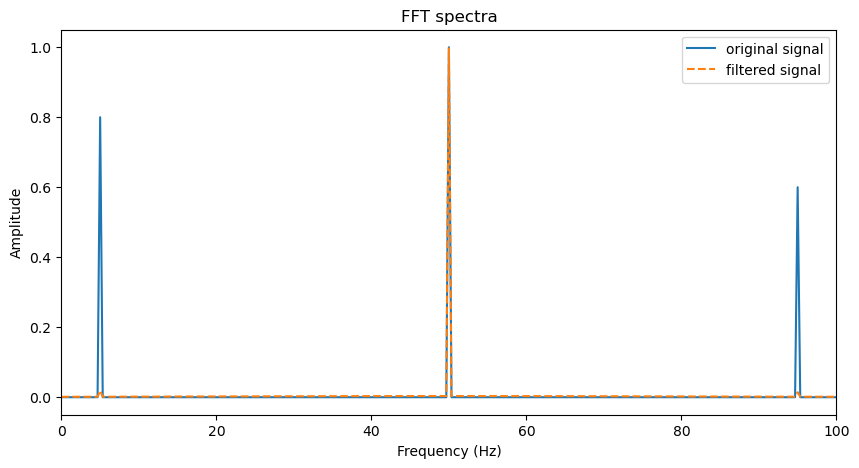

In [18]:
fir_out = lfilter(b_new1, [1], x)

freq_fft = np.fft.rfftfreq(N, d=1/fs)
amplitude_fir_fft = np.abs(np.fft.rfft(fir_out)) / N
amplitude_fir_fft[1:-1] *= 2
amplitude_fft = np.abs(np.fft.rfft(x)) / N
amplitude_fft[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq_fft, amplitude_fft, label = "original signal")
plt.plot(freq_fft, amplitude_fir_fft, label = "filtered signal", linestyle = "--")
plt.title("FFT spectra")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.xlim(0, 100)
plt.legend()
plt.show()


### plotting signals in time domain

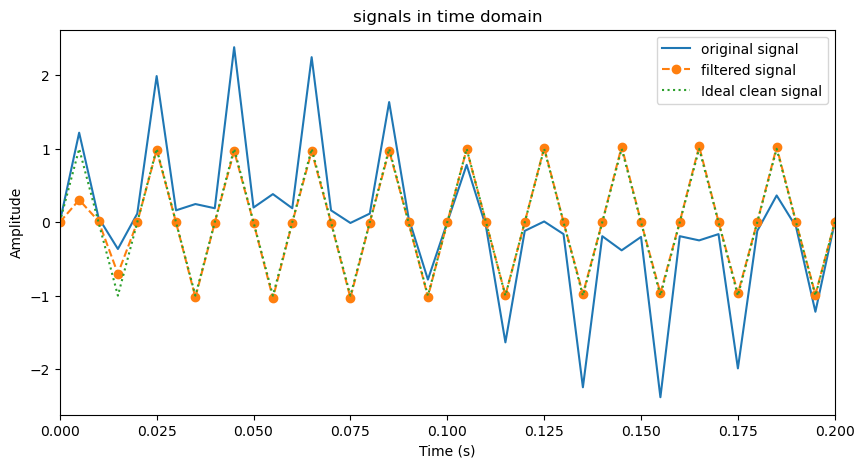

In [24]:
plt.figure(figsize=(10, 5))
plt.plot(t, x, label = "original signal")
plt.plot(t, fir_out, label = "filtered signal", linestyle = "--", marker = "o")
plt.plot(t, useful, label="Ideal clean signal", linestyle = ":")
plt.title("signals in time domain")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.xlim(0, 0.2)
plt.legend()
plt.show()

Notice: At the beginning, the orange filtered signal does not match the green ideal signal. This is mainly caused by the filter's startup transient. 
Because, the filter needs the current sample and samples from two and four time steps earlier.